Ran LU - Paris Saclay M2 AI - ran.lu@universite-paris-saclay.fr

# Task 3 - Spatial image filtering

This notebook loads `data/barbara.jpg`, converts it to grayscale, and applies four spatial-domain filters: a finite-difference gradient, Sobel edge detection, uniform averaging, and Gaussian smoothing.

## Setup and input image

,File,Width,Height,Minimum intensity,Maximum intensity,Mean intensity,Standard deviation
0,data/barbara.jpg,512,512,0.051,0.9373,0.4363,0.1876


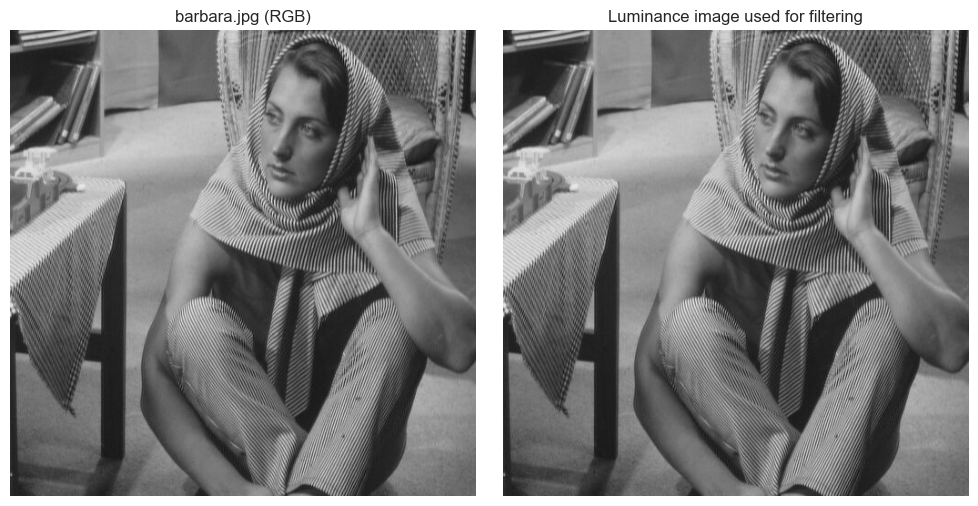

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from scipy import ndimage

plt.style.use("seaborn-v0_8-whitegrid")

IMAGE_PATH = Path("data/barbara.jpg")
rgb = np.asarray(Image.open(IMAGE_PATH).convert("RGB"), dtype=np.float64) / 255.0
image = rgb @ np.array([0.2126, 0.7152, 0.0722])

image_summary = pd.DataFrame({
    "File": [str(IMAGE_PATH)],
    "Width": [image.shape[1]],
    "Height": [image.shape[0]],
    "Minimum intensity": [image.min()],
    "Maximum intensity": [image.max()],
    "Mean intensity": [image.mean()],
    "Standard deviation": [image.std()],
})
display(image_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(rgb)
axes[0].set_title("barbara.jpg (RGB)")
axes[0].axis("off")
axes[1].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Luminance image used for filtering")
axes[1].axis("off")
fig.tight_layout()
plt.show()

### Result analysis

`barbara.jpg` is a 512×512 RGB image. Its grayscale luminance ranges from 0.0510 to 0.9373, with mean 0.4363 and standard deviation 0.1876. The face and background contain relatively smooth regions, while the scarf, trousers, chair, tablecloth, and bookshelf contain strong boundaries and dense stripe textures. This mixture is well suited to comparing high-pass edge filters with low-pass smoothers.

### Code analysis

Pillow loads the real JPEG and explicitly converts it to RGB. The dot product applies Rec. 709 luminance weights ([0.2126,0.7152,0.0722]), producing one floating-point channel in ([0,1]). Using an explicit conversion keeps all four filters on the same intensity representation.

## 1. Gradient filter

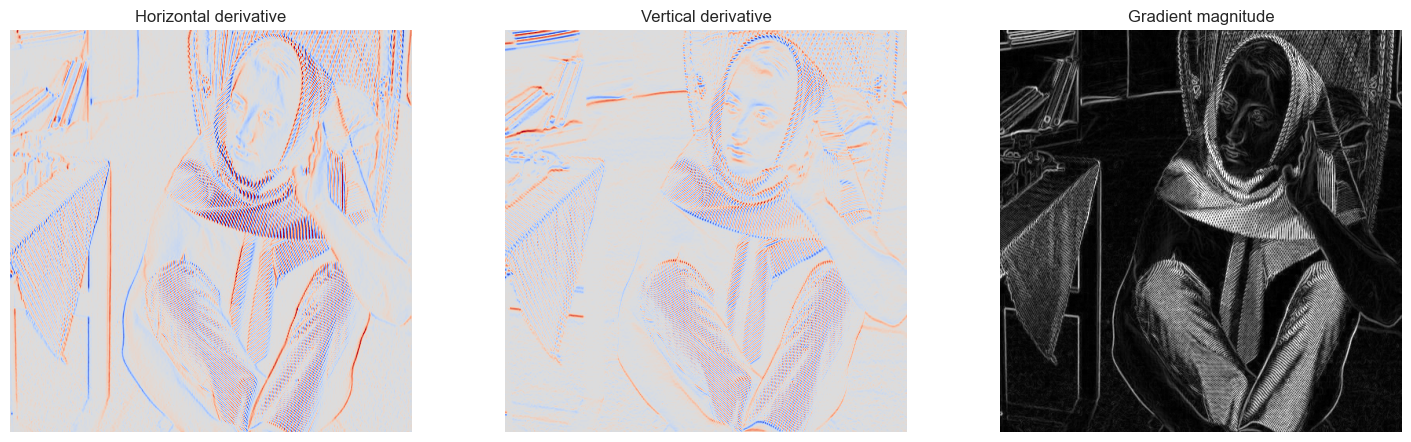

In [2]:
gradient_x = ndimage.correlate(image, np.array([[-1, 0, 1]]) / 2, mode="reflect")
gradient_y = ndimage.correlate(image, np.array([[-1], [0], [1]]) / 2, mode="reflect")
gradient_magnitude = np.hypot(gradient_x, gradient_y)
derivative_limit = max(np.percentile(np.abs(gradient_x), 99), np.percentile(np.abs(gradient_y), 99))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(gradient_x, cmap="coolwarm", vmin=-derivative_limit, vmax=derivative_limit)
axes[0].set_title("Horizontal derivative")
axes[1].imshow(gradient_y, cmap="coolwarm", vmin=-derivative_limit, vmax=derivative_limit)
axes[1].set_title("Vertical derivative")
axes[2].imshow(gradient_magnitude, cmap="gray", vmax=np.percentile(gradient_magnitude, 99.5))
axes[2].set_title("Gradient magnitude")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

### Result analysis

The directional derivatives separate vertical and horizontal intensity transitions. Their magnitude highlights the face contour, arm, chair frame, table edge, and the dense stripes in the clothing and tablecloth. Smooth facial and background regions remain dark. The magnitude has mean 0.0467 and standard deviation 0.0560, showing that strong responses occupy a relatively small fraction of the image.

### Code analysis

The centered ([-1,0,1]/2) kernels estimate first derivatives through spatial correlation. Reflected boundaries avoid artificial dark borders, while `np.hypot` forms an orientation-independent magnitude. Symmetric color limits preserve derivative sign in the directional views; percentile clipping prevents a few JPEG or edge outliers from hiding weaker structure.

## 2. Sobel filter

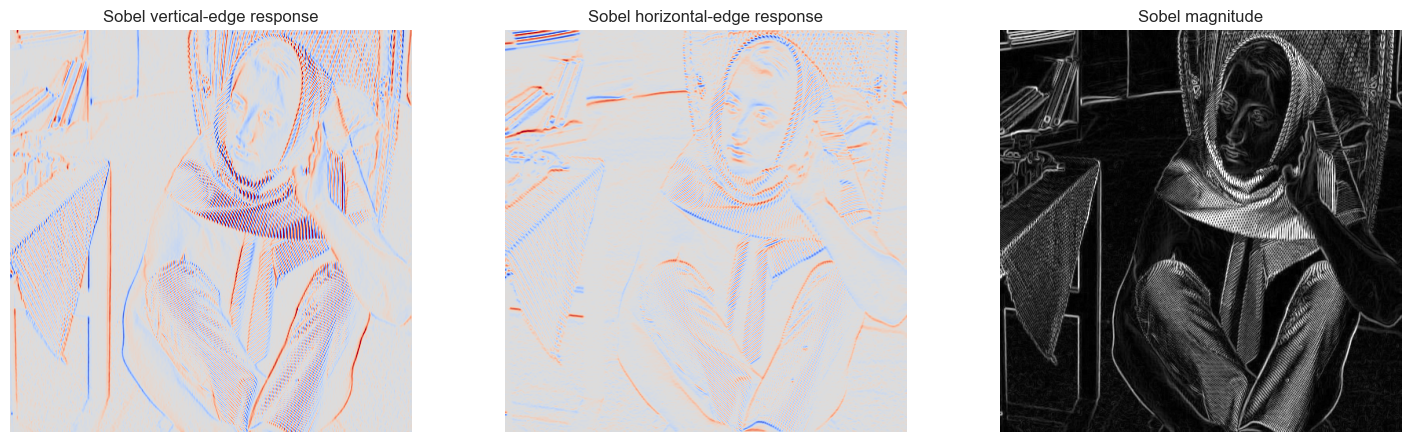

In [3]:
sobel_x = ndimage.sobel(image, axis=1, mode="reflect")
sobel_y = ndimage.sobel(image, axis=0, mode="reflect")
sobel_magnitude = np.hypot(sobel_x, sobel_y)
sobel_limit = max(np.percentile(np.abs(sobel_x), 99), np.percentile(np.abs(sobel_y), 99))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(sobel_x, cmap="coolwarm", vmin=-sobel_limit, vmax=sobel_limit)
axes[0].set_title("Sobel vertical-edge response")
axes[1].imshow(sobel_y, cmap="coolwarm", vmin=-sobel_limit, vmax=sobel_limit)
axes[1].set_title("Sobel horizontal-edge response")
axes[2].imshow(sobel_magnitude, cmap="gray", vmax=np.percentile(sobel_magnitude, 99.5))
axes[2].set_title("Sobel magnitude")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

### Result analysis

Sobel filtering preserves the principal contours and the repeated fabric stripes while suppressing more isolated pixel-scale variation than the simple derivative. The magnitude mean is 0.2949 and its standard deviation is 0.3500. These values are larger than the finite-difference values because SciPy's Sobel kernel is not normalized to the same gain, so the raw magnitudes should not be compared as an edge-quality score.

### Code analysis

`ndimage.sobel` combines a first derivative in one direction with ([1,2,1]) smoothing in the perpendicular direction. Signed responses are shown with a diverging colormap and combined only afterward. The shared percentile limits make the two directional panels visually comparable.

## 3. Averaging filter

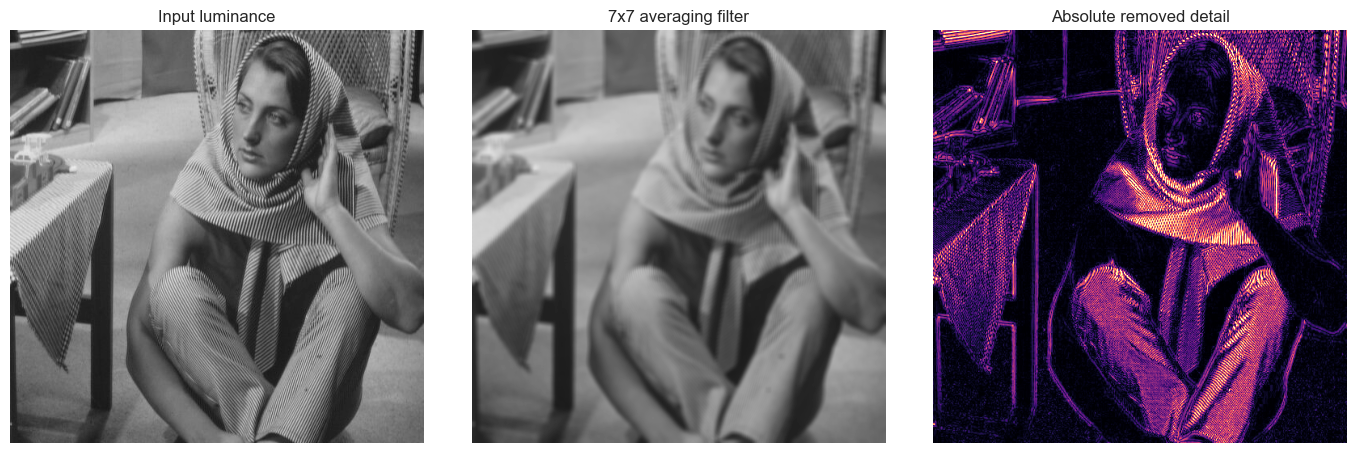

In [4]:
average_size = 7
average_image = ndimage.uniform_filter(image, size=average_size, mode="reflect")
average_residual = image - average_image

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Input luminance")
axes[1].imshow(average_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"{average_size}x{average_size} averaging filter")
axes[2].imshow(np.abs(average_residual), cmap="magma", vmax=np.percentile(np.abs(average_residual), 99))
axes[2].set_title("Absolute removed detail")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

### Result analysis

The 7×7 average reduces the grayscale standard deviation from 0.1876 to 0.1701 and has an RMSE of 0.0671 from the input. Fine scarf, trouser, chair, and tablecloth stripes merge into smoother bands, while the face and broad background remain recognizable. Sharp contours widen because every sample within the square window has equal weight.

### Code analysis

`uniform_filter` efficiently implements convolution with a normalized 7×7 all-ones kernel. Reflected boundaries preserve content near the image frame. The absolute residual panel explicitly shows which high-frequency details the low-pass operation removes rather than relying only on side-by-side visual inspection.

## 4. Gaussian filter

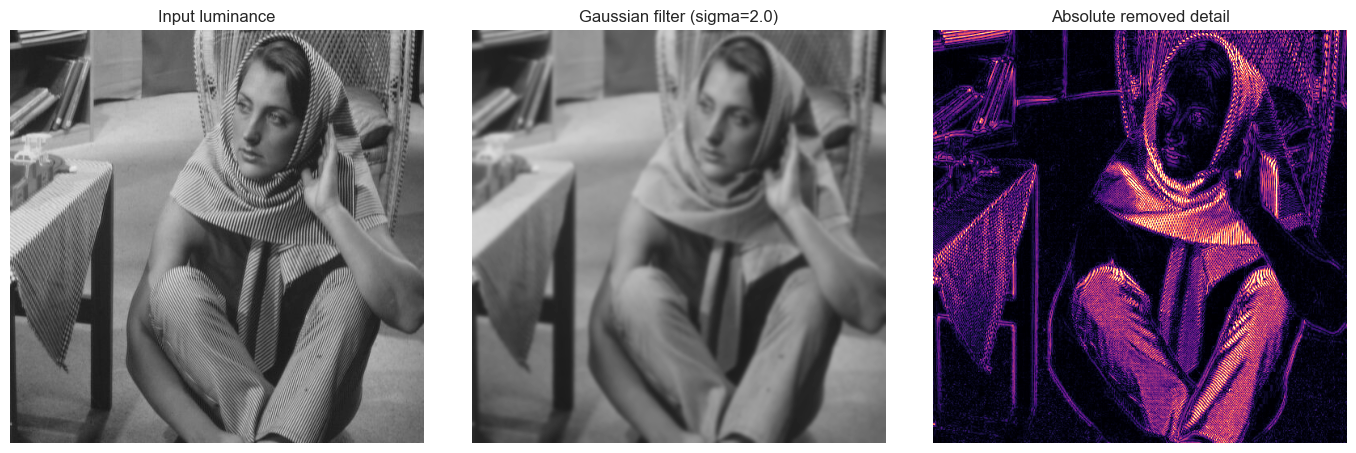

In [5]:
gaussian_sigma = 2.0
gaussian_image = ndimage.gaussian_filter(image, sigma=gaussian_sigma, mode="reflect")
gaussian_residual = image - gaussian_image

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Input luminance")
axes[1].imshow(gaussian_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Gaussian filter (sigma={gaussian_sigma})")
axes[2].imshow(np.abs(gaussian_residual), cmap="magma", vmax=np.percentile(np.abs(gaussian_residual), 99))
axes[2].set_title("Absolute removed detail")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

### Result analysis

Gaussian smoothing reduces the standard deviation to 0.1703 and gives an RMSE of 0.0648 from the input. It suppresses the high-frequency textile stripes and JPEG-scale variation while retaining the face and large object boundaries. Compared with the 7x7 average, the change is spatially smoother because nearby pixels receive more weight than distant pixels.

### Code analysis

`gaussian_filter` performs separable Gaussian convolution with sigma 2 in both dimensions. The reflected boundary convention matches the averaging experiment. The residual is displayed using the same percentile strategy so removed fine detail remains visible without being dominated by a few strong edges.

## Overall comparison

,Filter,Role,Mean,Standard deviation,RMSE from input
0,Gradient magnitude,High-pass edge detector,0.0467,0.0560,NaN
1,Sobel magnitude,High-pass edge detector,0.2949,0.3500,NaN
2,Averaging,Low-pass smoother,0.4363,0.1701,0.0671
3,Gaussian,Low-pass smoother,0.4363,0.1703,0.0648


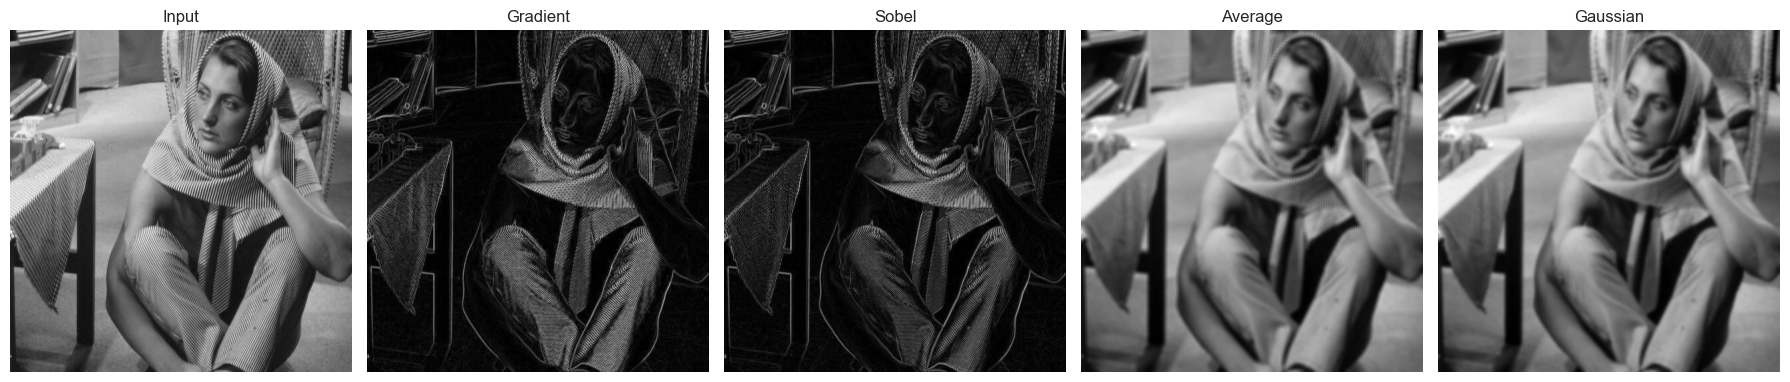

In [6]:
summary = pd.DataFrame({
    "Filter": ["Gradient magnitude", "Sobel magnitude", "Averaging", "Gaussian"],
    "Role": ["High-pass edge detector", "High-pass edge detector", "Low-pass smoother", "Low-pass smoother"],
    "Mean": [gradient_magnitude.mean(), sobel_magnitude.mean(), average_image.mean(), gaussian_image.mean()],
    "Standard deviation": [gradient_magnitude.std(), sobel_magnitude.std(), average_image.std(), gaussian_image.std()],
    "RMSE from input": [np.nan, np.nan, np.sqrt(np.mean(average_residual**2)), np.sqrt(np.mean(gaussian_residual**2))],
})
display(summary.round(4))

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
images = [image, gradient_magnitude, sobel_magnitude, average_image, gaussian_image]
titles = ["Input", "Gradient", "Sobel", "Average", "Gaussian"]
for ax, result, title in zip(axes, images, titles):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()

### Result analysis

On Barbara, the gradient and Sobel filters concentrate energy around object contours and the repeated textile patterns, confirming their high-pass role. The smoothing filters preserve the mean luminance at 0.4363 while reducing standard deviation from 0.1876 to about 0.170. Gaussian smoothing has a slightly lower input RMSE (0.0648) than 7×7 averaging (0.0671), and visually produces softer transitions with less box-shaped spreading.

### Code analysis

The summary reports common descriptive statistics, but the gradient and Sobel magnitudes have different kernel gains and should not be ranked by their raw means. RMSE is included only for the two outputs that remain intensity images. The final panel uses identical source data and display layout for a direct qualitative comparison.

### Conclusion

The real image demonstrates the expected separation: gradient and Sobel filters expose boundaries and high-frequency fabric patterns, while averaging and Gaussian filters suppress those components. Sobel is less sensitive to isolated variation than the basic derivative, and Gaussian weighting gives more natural smoothing than a uniform square window.